# Лабораторная работа №3

In [1]:
import numpy as np
import pandas as pd
import sympy as sp
import matplotlib.pyplot as plt


## 3.1 Интерполяционные многочлены Лагранжа и Ньютона

### Вариант 18

```tetx
y = sqrt(x) + x
a) interpolation_points = 0, 1.7, 3.4, 5.1
b) interpolation_points = 0, 1.7, 4.0, 5.1
X* = 3.0
```

In [2]:
xs = sp.symbols('x')

def y_func(x):
    return np.sqrt(x) + x


def lagrange_interpolation(x, interpolation_points):
    res = 0.0
    y = y_func(interpolation_points)
    n = len(interpolation_points)

    for i in range(n):
        product = 1.0
        for j in range(n):
            if j == i:
                continue
            product *= (x - interpolation_points[j]) / (interpolation_points[i] - interpolation_points[j])
        res += y[i] * product

    return res


def lagrange_polynomial(interpolation_points):
    x = sp.symbols('x')
    y = y_func(interpolation_points)
    n = len(interpolation_points)
    L = 0
    for i in range(n):
        term = 1
        for j in range(n):
            if j == i:
                continue
            term *= (x - interpolation_points[j]) / (interpolation_points[i] - interpolation_points[j])
        L += y[i] * term
    return sp.expand(L)


def divided_differences(interpolation_points):

    n = len(interpolation_points)
    y = y_func(interpolation_points)

    table = np.zeros((n, n))
    table[:, 0] = y

    for k in range(1, n):
        for i in range(n - k):
            table[i][k] = (table[i + 1][k - 1] - table[i][k - 1]) / (interpolation_points[i + k] - interpolation_points[i])
    return table


def newton_polynomial(interpolation_points):
    x = sp.symbols('x')
    table = divided_differences(interpolation_points)
    n = len(interpolation_points)

    P = table[0, 0]
    prod = 1
    for k in range(1, n):
        prod *= (x - interpolation_points[k - 1])
        P += table[0, k] * prod
    return sp.expand(P)


def newton_interpolation(x, interpolation_points):

    table = divided_differences(interpolation_points)
    n = len(interpolation_points)

    coeffs = table[0, :]

    res = coeffs[n - 1]
    for k in range(n - 2, -1, -1):
        res = coeffs[k] + (x - interpolation_points[k]) * res
    return res



def print_divided_differences_table(interpolation_points):
    table = divided_differences(interpolation_points)
    n = len(interpolation_points)

    header = "   x_i   |    f(x_i)    " + "".join(
        f"|  Δ^{k}        " for k in range(1, n)
    )
    print(header)
    print("-" * len(header))

    for i in range(n):
        row = f"{interpolation_points[i]:8.4f} | {table[i, 0]:12.6f} "
        for k in range(1, n - i):
            row += f"| {table[i, k]:12.6f} "
        print(row)


### Демонсрация

In [3]:
interpolation_points1 = np.array([0, 1.7, 3.4, 5.1])
interpolation_points2 = np.array([0, 1.7, 4.0, 5.1])
x_star = 3.0
print("Узлы интерполяции")
y1 = y_func(interpolation_points1)
y2 = y_func(interpolation_points2)
print('1')
print('x\t f(x)')
for i in range(len(interpolation_points1)):
    print(interpolation_points1[i], '|', y1[i])
    
print('\n2')
print('x\t f(x)')
for i in range(len(interpolation_points2)):
    print(interpolation_points2[i], '|',  y2[i])

Узлы интерполяции
1
x	 f(x)
0.0 | 0.0
1.7 | 3.0038404810405295
3.4 | 5.243908891458577
5.1 | 7.358317958127243

2
x	 f(x)
0.0 | 0.0
1.7 | 3.0038404810405295
4.0 | 6.0
5.1 | 7.358317958127243


In [4]:
print("Интерполяционные многочлены Лагранжа")
L1 = lagrange_polynomial(interpolation_points1)
L2 = lagrange_polynomial(interpolation_points2)
print(f"1: {L1}")
print(f"2: {L2}")


Интерполяционные многочлены Лагранжа
1: 0.0216470834816847*x**3 - 0.242540622404081*x**2 + 2.11672397567224*x
2: 0.0188466177753101*x**3 - 0.223497455600733*x**2 + 2.09244393799797*x


In [5]:
print("Таблица разделённых разностей 1:")
print_divided_differences_table(interpolation_points1)
print("Таблица разделённых разностей 2:")
print_divided_differences_table(interpolation_points2)

Таблица разделённых разностей 1:
   x_i   |    f(x_i)    |  Δ^1        |  Δ^2        |  Δ^3        
------------------------------------------------------------------
  0.0000 |     0.000000 |     1.766965 |    -0.132140 |     0.021647 
  1.7000 |     3.003840 |     1.317687 |    -0.021740 
  3.4000 |     5.243909 |     1.243770 
  5.1000 |     7.358318 
Таблица разделённых разностей 2:
   x_i   |    f(x_i)    |  Δ^1        |  Δ^2        |  Δ^3        
------------------------------------------------------------------
  0.0000 |     0.000000 |     1.766965 |    -0.116072 |     0.018847 
  1.7000 |     3.003840 |     1.302678 |    -0.019954 
  4.0000 |     6.000000 |     1.234835 
  5.1000 |     7.358318 


In [6]:
print("Интерполяционные многочлены Ньютона")
P1 = newton_polynomial(interpolation_points1)
P2 = newton_polynomial(interpolation_points2)
print(f"1: {P1}")
print(f"2: {P2}")

Интерполяционные многочлены Ньютона
1: 0.0216470834816846*x**3 - 0.24254062240408*x**2 + 2.11672397567224*x
2: 0.01884661777531*x**3 - 0.223497455600733*x**2 + 2.09244393799797*x


In [7]:
print("Значения в x*")
y_star = y_func(x_star)
l1 = lagrange_interpolation(x_star, interpolation_points1)
l2 = lagrange_interpolation(x_star, interpolation_points2)
p1 = newton_interpolation(x_star, interpolation_points1)
p2 = newton_interpolation(x_star, interpolation_points2)
print(f'f(x): {y_star}')
print(f'L1:   {l1}')
print(f'L2:   {l2}')
print(f'P1:   {p1}')
print(f'P2:   {p2}')

Значения в x*
f(x): 4.732050807568877
L1:   4.75177757938548
L2:   4.774713393520687
P1:   4.751777579385479
P2:   4.7747133935206865


In [8]:
print('Абсолютная погрешность интерполяции')
print(f'L1: {np.abs(y_star - l1)}')
print(f'L2: {np.abs(y_star - l2)}')
print(f'P1: {np.abs(y_star - p1)}')
print(f'P2: {np.abs(y_star - p2)}')
print()
print('Разность между результатами')
print(f'1: {np.abs(l1 - p1)}')
print(f'2: {np.abs(l2 - p2)}')

Абсолютная погрешность интерполяции
L1: 0.019726771816602984
L2: 0.042662585951810605
P1: 0.019726771816602096
P2: 0.04266258595180972

Разность между результатами
1: 8.881784197001252e-16
2: 8.881784197001252e-16


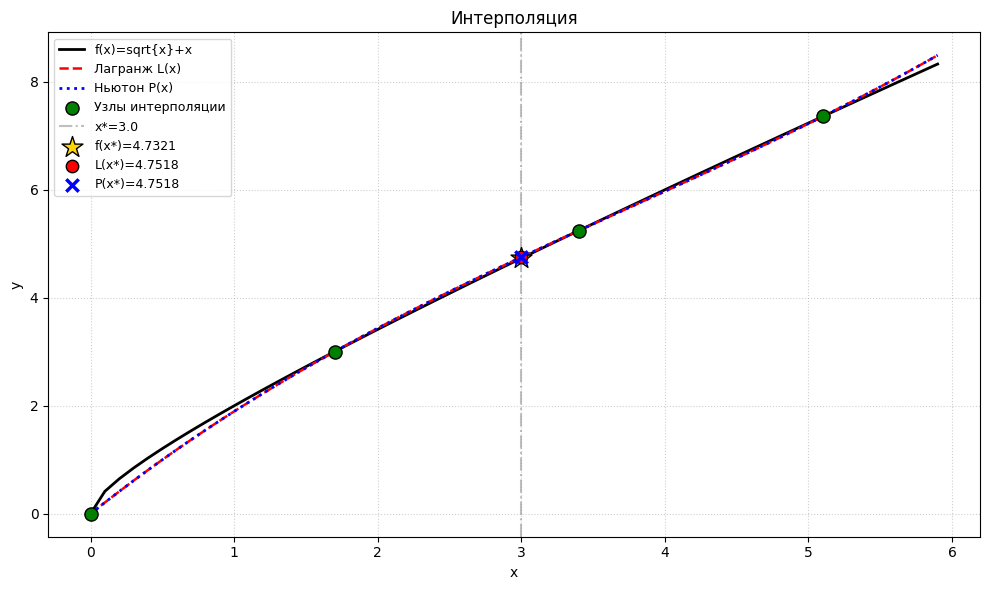

In [9]:
x = np.arange(0, 6, 0.1)
y = y_func(x)

l = x.copy()
for i in range(len(l)):
    l[i] = lagrange_interpolation(l[i], interpolation_points1)
    
p = x.copy()
for i in range(len(p)):
    p[i] = newton_interpolation(p[i], interpolation_points1)


f_star = y_func(np.array([x_star]))[0]
L_star = lagrange_interpolation(x_star, interpolation_points1)
N_star = newton_interpolation(x_star, interpolation_points1)

plt.figure(figsize=(10, 6))
plt.plot(x, y_func(x), 'k-', lw=2,   label='f(x)=sqrt{x}+x')
plt.plot(x, l, 'r--', lw=1.8, label='Лагранж L(x)')
plt.plot(x, p, 'b:', lw=2,   label='Ньютон P(x)')
plt.scatter(interpolation_points1, y_func(interpolation_points1), s=90, color='green', ec='black', zorder=5, label='Узлы интерполяции')
plt.axvline(x_star, color='gray', ls='-.', alpha=.5, label=f'x*={x_star}')
plt.scatter([x_star], [f_star], s=250, marker='*', color='gold', ec='black', zorder=6, label=f'f(x*)={f_star:.4f}')
plt.scatter([x_star], [L_star], s=80,  marker='o', color='red',  ec='black', zorder=7, label=f'L(x*)={L_star:.4f}')
plt.scatter([x_star], [N_star], s=80,  marker='x', color='blue', lw=2.5,     zorder=7, label=f'P(x*)={N_star:.4f}')

plt.title('Интерполяция')
plt.xlabel('x')
plt.ylabel('y')
plt.grid(ls=':', alpha=.6)
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 3.2 Кубический сплайн

### Вариант 18

X* = 3.0

| i | 0 | 1 | 2 | 3 | 4 |
|---|---|---|---|---|---|
| x | 0.0 | 1.7 | 3.4 | 5.1 | 6.8 |
| f(x) | 0.0 | 3.0038 | 5.2439 | 7.3583 | 9.4077 |


In [ ]:
def natural_cubic_spline(x, y, x_eval):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    n = len(x) - 1
    h = np.diff(x)

    c = np.zeros(n + 1)
    if n > 1:
        m = n - 1
        A = np.zeros((m, m))
        rhs = np.zeros(m)
        for i in range(1, n):
            row = i - 1
            if i - 1 >= 1:
                A[row, row - 1] = h[i - 1]
            A[row, row] = 2.0 * (h[i - 1] + h[i])
            if i + 1 <= n - 1:
                A[row, row + 1] = h[i]
            rhs[row] = 3.0 * ((y[i + 1] - y[i]) / h[i] - (y[i] - y[i - 1]) / h[i - 1])
        c[1:n] = np.linalg.solve(A, rhs)

    a = y[:-1].copy()
    b = np.zeros(n)
    d = np.zeros(n)
    for i in range(n):
        b[i] = (y[i + 1] - y[i]) / h[i] - h[i] * (2 * c[i] + c[i + 1]) / 3.0
        d[i] = (c[i + 1] - c[i]) / (3.0 * h[i])

    coeffs = [(a[i], b[i], c[i], d[i]) for i in range(n)]

    def find_interval(xp):
        if xp <= x[0]:
            return 0
        if xp >= x[-1]:
            return n - 1
        return int(np.searchsorted(x, xp, side='right') - 1)

    def S_point(xp):
        i = find_interval(xp)
        dx = xp - x[i]
        a_i, b_i, c_i, d_i = coeffs[i]
        return a_i + b_i * dx + c_i * dx**2 + d_i * dx**3

    def S_second(xp):
        i = find_interval(xp)
        dx = xp - x[i]
        a_i, b_i, c_i, d_i = coeffs[i]
        return 2.0 * c_i + 6.0 * d_i * dx

    if np.isscalar(x_eval):
        value = S_point(x_eval)
        interval = find_interval(x_eval)
        return value, interval, coeffs, c, S_point, S_second
    else:
        values = np.array([S_point(xp) for xp in x_eval])
        return values, None, coeffs, c, S_point, S_second

### Демонстрация

In [11]:
x_nodes = np.array([0, 1.7, 3.4, 5.1, 6.8])
y_nodes = np.array([0.0, 3.0038, 5.2439, 7.3583, 9.4077])

x_star = 3.0

print('Исходные узлы и значения')
print(f'x: {x_nodes}')
print(f'y: {y_nodes}')

Исходные узлы и значения
x: [0.  1.7 3.4 5.1 6.8]
y: [0.     3.0038 5.2439 7.3583 9.4077]


In [12]:
value, interval, coeffs, c, S_point, S_second = natural_cubic_spline(x_nodes, y_nodes, x_star)

print("Коэффициенты и интервалы действия")
header = f"   {'i':>3} | {'Интервал':^17} | {'a_i':>10} | {'b_i':>10} | {'c_i':>10} | {'d_i':>10}"
print(header)
print("   " + "-" * (len(header) - 3))
for i, (a_i, b_i, c_i, d_i) in enumerate(coeffs):
    interval_str = f"[{x_nodes[i]:.3f}, {x_nodes[i+1]:.3f}]"
    print(f"   {i:>3} | {interval_str:^17} | {a_i:>10.5f} | {b_i:>10.5f} | {c_i:>10.5f} | {d_i:>10.5f}")

Коэффициенты и интервалы действия
     i |     Интервал      |        a_i |        b_i |        c_i |        d_i
   ---------------------------------------------------------------------------
     0 |  [0.000, 1.700]   |    0.00000 |    1.88267 |    0.00000 |   -0.04005
     1 |  [1.700, 3.400]   |    3.00380 |    1.53548 |   -0.20423 |    0.04478
     2 |  [3.400, 5.100]   |    5.24390 |    1.22936 |    0.02416 |   -0.00923
     3 |  [5.100, 6.800]   |    7.35830 |    1.23149 |   -0.02291 |    0.00449


In [13]:
print(f'Значение в x*: {value}')
print(f"Номер интервала: {interval}, интервал: [{x_nodes[interval]}, {x_nodes[interval+1]}]")

Значение в x*: 4.753156051001716
Номер интервала: 1, интервал: [1.7, 3.4]


In [14]:
print("Прохождение сплайна через узлы")
max_err = 0.0
for i, (xi, yi) in enumerate(zip(x_nodes, y_nodes)):
    s_val = S_point(xi)
    err = abs(s_val - yi)
    max_err = max(max_err, err)
print(f"Максимальная погрешность в узлах: {max_err:.12f}")

Прохождение сплайна через узлы
Максимальная погрешность в узлах: 0.000000000000


In [15]:
print("Вторые производные S''(x_i) = 2·c_i во всех узлах:")
print(f"{'i':>3} | {'x_i':>10} | {'c_i':>14} | 'S\"(x_i)=2c_i'")
print("-" * 50)
for i in range(len(x_nodes)):
    print(f"{i:>3} | {x_nodes[i]:>10.5f} | {c[i]:>14.6f} | {2*c[i]:>16.6f}")

Вторые производные S''(x_i) = 2·c_i во всех узлах:
  i |        x_i |            c_i | 'S"(x_i)=2c_i'
--------------------------------------------------
  0 |    0.00000 |       0.000000 |         0.000000
  1 |    1.70000 |      -0.204233 |        -0.408466
  2 |    3.40000 |       0.024165 |         0.048329
  3 |    5.10000 |      -0.022910 |        -0.045819
  4 |    6.80000 |       0.000000 |         0.000000


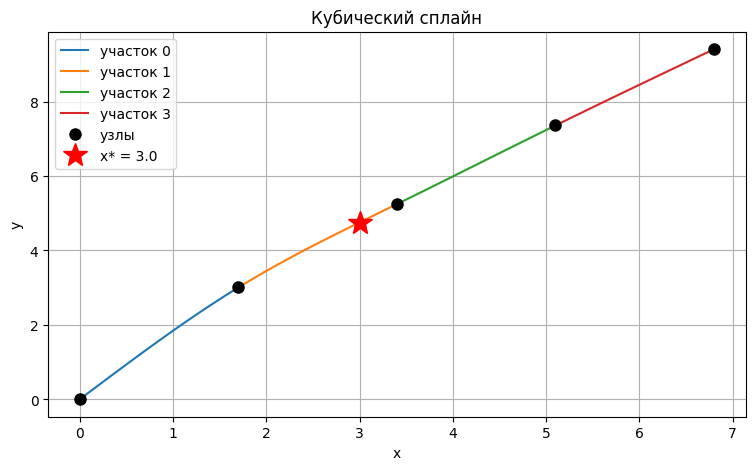

In [16]:
plt.figure(figsize=(9, 5))

for i in range(len(coeffs)):
    xs = np.linspace(x_nodes[i], x_nodes[i+1], 100)
    a, b, c, d = coeffs[i]
    ys = a + b*(xs-x_nodes[i]) + c*(xs-x_nodes[i])**2 + d*(xs-x_nodes[i])**3
    plt.plot(xs, ys, label=f"участок {i}")

plt.plot(x_nodes, y_nodes, 'ko', markersize=8, label='узлы')

plt.plot(x_star, y_star, 'r*', markersize=18, label=f'x* = {x_star}')

plt.grid(True)
plt.legend()
plt.xlabel('x')
plt.ylabel('y')
plt.title('Кубический сплайн')
plt.show()

## 3.3 Метод наименьших квадратов
### Вариант 18
 
|i|0|	1|	2|	3|	4|	5|
|--|--|--|---|---|---|---| 
|x| 0.0|	1.7|	3.4|	5.1|	6.8|	8.5| 
|y| 0.0|	3.0038|	5.2439|	7.3583|	9.4077|	11.415|


In [17]:
xs = sp.symbols('x')

def build_approximation(x_vals, y_vals, degree):
    x_arr = np.asarray(x_vals, dtype=float)
    y_arr = np.asarray(y_vals, dtype=float)

    V = np.vander(x_arr, degree + 1, increasing=True)

    coeffs, *_ = np.linalg.lstsq(V, y_arr, rcond=None)

    P = sum(sp.Float(c) * xs**i for i, c in enumerate(coeffs))
    P = sp.expand(P)

    y_pred = V @ coeffs
    err = float(np.mean((y_arr - y_pred) ** 2))

    return P, coeffs, err

### Демонстрация

In [18]:
x = [0.0, 1.7,	3.4, 5.1, 6.8, 8.5]
y = [0.0, 3.0038, 5.2439, 7.3583, 9.4077, 11.415]

print("Исходные точки:")
for xi, yi in zip(x, y):
    print(f"({xi}; {yi})")

res = {}

for i in range(1, 4):
    res[i] = build_approximation(x, y, i)



Исходные точки:
(0.0; 0.0)
(1.7; 3.0038)
(3.4; 5.2439)
(5.1; 7.3583)
(6.8; 9.4077)
(8.5; 11.415)


In [19]:
print("Многочлены и их коэффициенты")
for i in range(1, 4):
    print(f'P{i}(x) = {res[i][0]}')
    print(f'Коэффициенты: {res[i][1]}')
    print(f'MSE{i} = {res[i][2]}\n')

Многочлены и их коэффициенты
P1(x) = 1.31766554621849*x + 0.471371428571428
Коэффициенты: [0.47137143 1.31766555]
MSE1 = 0.08123836628571439

P2(x) = -0.0354998764211565*x**2 + 1.61941449579832*x + 0.129389285714284
Коэффициенты: [ 0.12938929  1.6194145  -0.03549988]
MSE2 = 0.015745366107142764

P3(x) = 0.00714299176033317*x**3 - 0.126573021365409*x**2 + 1.9022269685652*x + 0.0241087301586941
Коэффициенты: [ 0.02410873  1.90222697 -0.12657302  0.00714299]
MSE3 = 0.0024445716534391483



In [20]:
print('Сравнение ошибок')
min_err = res[1][2]
min_id = 1
for i in range(2, 4):
    if res[i][2] < min_err:
        min_err = res[i][2]
        min_id = i

print(f'Лучшее приближение дает многочлен P{min_id}(x). Ошибка: {min_err}')

Сравнение ошибок
Лучшее приближение дает многочлен P3(x). Ошибка: 0.0024445716534391483


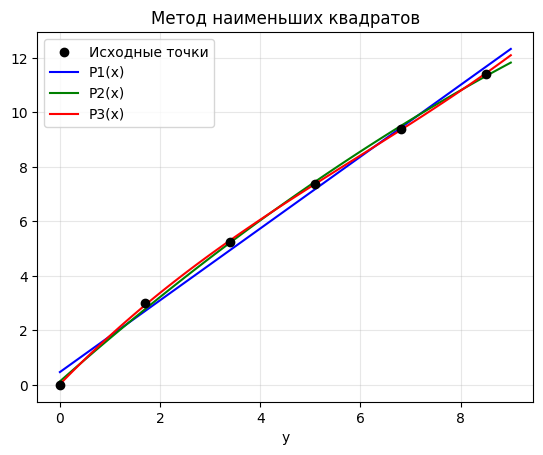

In [21]:
x_arr = np.array([0.0, 1.7,	3.4, 5.1, 6.8, 8.5])
y_arr = np.array([0.0, 3.0038, 5.2439, 7.3583, 9.4077, 11.415])

x_smooth = np.linspace(0, 9, 100)

p1 = sp.lambdify(xs, res[1][0])
p2 = sp.lambdify(xs, res[2][0])
p3 = sp.lambdify(xs, res[3][0])

plt.scatter(x_arr, y_arr, color='black', zorder=5, label='Исходные точки')
plt.plot(x_smooth, p1(x_smooth), color='blue', label='P1(x)')
plt.plot(x_smooth, p2(x_smooth), color='green', label='P2(x)')
plt.plot(x_smooth, p3(x_smooth), color='red', label='P3(x)')

plt.xlabel('x')
plt.xlabel('y')
plt.title('Метод наименьших квадратов')
plt.grid(alpha=0.3)
plt.legend()
plt.show()


## 3.4 Численное дифференцирование

### Вариант 18

X* = 0.2

 
|i|0|	1|	2|	3|	4|
|---|-|--|---|---|---|
|x|-0.2| 	0.0|	0.2| 	0.4| 	0.6| 
|y|1.5722|	1.5708|	1.5694|	1.5593|	1.5273|


In [22]:
def numerical_diff_h(x_nodes, y_nodes, x_eval):

    idx = np.searchsorted(x_nodes, x_eval)
    
    if idx >= len(x_nodes) - 2:
        idx = len(x_nodes) - 3
    if idx < 0:
        idx = 0
        
    x_i = x_nodes[idx]
    x_i1 = x_nodes[idx+1]
    x_i2 = x_nodes[idx+2]
    
    y_i = y_nodes[idx]
    y_i1 = y_nodes[idx+1]
    y_i2 = y_nodes[idx+2]
    
    h = x_i1 - x_i # Шаг
    
    term1 = (y_i1 - y_i) / h
    term2 = (y_i2 - 2*y_i1 + y_i) / (2 * h**2)
    term3 = (2 * x_eval - x_i - x_i1)
    
    dy = term1 + term2 * term3
    
    d2y = (y_i2 - 2*y_i1 + y_i) / (h**2)
    
    return dy, d2y, [x_i, x_i1, x_i2], [y_i, y_i1, y_i2]

### Демонстрация

In [23]:
x_arr =  [-0.2, 0.0, 0.2, 0.4, 0.6]
y_arr = [1.5722, 1.5708, 1.5694, 1.5593, 1.5273]
x_star = 0.2

print('Исходные узлы')
print(f'x: {x_arr}')
print(f'y: {y_arr}')
print(f'x* = {x_star}')

Исходные узлы
x: [-0.2, 0.0, 0.2, 0.4, 0.6]
y: [1.5722, 1.5708, 1.5694, 1.5593, 1.5273]
x* = 0.2


In [24]:
dy, d2y, xi, yi = numerical_diff_h(x_arr, y_arr, x_star)

print('Использованные узлы')
for pair in zip(xi, yi):
    print(pair)

print()
print(f'Первая производная y\' = {dy}')
print(f'Вторая производная производная y\'\' = {d2y}')

Использованные узлы
(0.2, 1.5694)
(0.4, 1.5593)
(0.6, 1.5273)

Первая производная y' = 0.004249999999999525
Вторая производная производная y'' = -0.5474999999999951


## 3.5 Численное интегрирование

### Вариант 18

```text
y = x / (16 - x^4)

X0 = -1
Xk = 1

h1 = 0.5
h2 = 0.25
```

In [25]:
def f(x):
    return x / (16 - x ** 4)


def left_rectangles(f, a, b, n):
    h = (b - a) / n
    s = 0.0
    for i in range(n):
        x = a + i * h
        s += f(x)
    return s * h


def right_rectangles(f, a, b, n):
    h = (b - a) / n
    s = 0.0
    for i in range(n):
        x = a + (i + 1) * h
        s += f(x)
    return s * h


def middle_rectangles(f, a, b, n):
    h = (b - a) / n
    s = 0.0
    for i in range(n):
        x = a + (i + 0.5) * h
        s += f(x)
    return s * h


def trapezoid(f, a, b, n):
    h = (b - a) / n
    s = 0.5 * (f(a) + f(b))
    for i in range(1, n):
        x = a + i * h
        s += f(x)
    return s * h


def simpson(f, a, b, n):
    if n % 2 != 0:
        n += 1
    h = (b - a) / n
    s = f(a) + f(b)
    for i in range(1, n):
        x = a + i * h
        if i % 2 == 0:
            s += 2 * f(x)
        else:
            s += 4 * f(x)
    return s * h / 3


def runge_romberg(I_h1, I_h2, p):
    k = 2
    return I_h2 + (I_h2 - I_h1) / (k ** p - 1)


def error_estimate(I_h1, I_h2, p):
    k = 2
    return abs(I_h1 - I_h2) / (k ** p - 1)

### Демонстрация

In [26]:
def build_table(f, a, b, n1, n2):
    methods = [
        ("Левые прямоугольники", left_rectangles, 1),
        ("Правые прямоугольники", right_rectangles, 1),
        ("Средние прямоугольники", middle_rectangles, 2),
        ("Трапеции", trapezoid, 2),
        ("Симпсон", simpson, 4),
    ]

    rows = []
    for name, method, p in methods:
        I_h1 = method(f, a, b, n1)
        I_h2 = method(f, a, b, n2)
        I_rr = runge_romberg(I_h1, I_h2, p)
        err  = error_estimate(I_h1, I_h2, p)
        rows.append({
            "Метод": name,
            "I(h1)": I_h1,
            "I(h2)": I_h2,
            "p": p,
            "Рунге–Ромберг": I_rr,
            "Погрешность (h2)": err,
        })
    return pd.DataFrame(rows)


x0, xk = -1, 1
h1, h2 = 0.5, 0.25

n1, n2 = int((xk - x0) / h1), int((xk - x0) / h2)

df = build_table(f, x0, xk, n1, n2)

df

,Метод,I(h1),I(h2),p,Рунге–Ромберг,Погрешность (h2)
0,Левые прямоугольники,-3.333333e-02,-1.666667e-02,1,6.938894e-18,1.666667e-02
1,Правые прямоугольники,3.333333e-02,1.666667e-02,1,-6.938894e-18,1.666667e-02
2,Средние прямоугольники,-3.469447e-18,1.734723e-18,2,3.469447e-18,1.734723e-18
3,Трапеции,0.000000e+00,-1.734723e-18,2,-2.312965e-18,5.782412e-19
4,Симпсон,0.000000e+00,-2.312965e-18,4,-2.467162e-18,1.541976e-19
